# Callable vs Puttable Bonds: Tree and Monte Carlo Valuation, ML Call Probabilities and Portfolio Optimisation

A callable bond lets the issuer repay early when rates fall, which is exactly when the investor would rather keep it. A puttable bond gives the investor the opposite right. One sign flip changes almost everything about how these bonds behave. This notebook values both, checks the engine against published durations for real municipal bonds, and builds a portfolio that earns yield without loading up on the callable bond's hidden risk.

**What it does.** It values bonds with embedded options with a Hull–White trinomial tree (QuantLib) and a Longstaff–Schwartz Monte Carlo cross-check.

It shows the key differences between the two: negative against positive convexity, opposite vega, and how price and duration react to rates. Machine learning then comes in four ways:

1. a **classifier of call-exercise probability** trained on optimal exercise decisions from simulated rate paths;
2. a **neural-network surrogate pricer** that values 7,500 real callable municipal bonds in seconds;
3. the surrogate's measure of how a rise in **volatility** changes their prices and yields;
4. a **portfolio optimiser** that targets yield while controlling negative convexity, stress-tested against rate and volatility shocks.

The engine is validated against the option-adjusted durations BlackRock publishes for the same bonds.

**Data.** iShares National Muni Bond ETF (MUB) holdings (prices, coupons, maturities, dated dates and the fund's option-adjusted and modified durations), the U.S. Treasury par yield curve, and the FRED 10-year yield for volatility.

**Methods.** A Hull–White one-factor tree (QuantLib `CallableFixedRateBond`, OAS, effective duration and convexity), Longstaff–Schwartz Monte Carlo, LightGBM and logistic classifiers, an MLP surrogate and linear programming (HiGHS).

**Key output.** Callable and puttable sensitivity profiles, the tree-against-Monte-Carlo check, agreement between model and published durations with the implied volatility, call probabilities by bond, the impact of +30% volatility on callable yields, and an optimised muni portfolio against a naive yield-maximiser under stress.

## 1. Callable and puttable bonds in one picture

A callable bond = straight bond − a Bermudan **call** option held by the issuer. A puttable bond = straight bond + a Bermudan **put** held by the investor. That one sign flip drives every difference:

| | Callable | Puttable |
|---|---|---|
| Price vs straight bond | lower (investor is short an option) | higher (investor is long an option) |
| When rates fall | price capped near the call price: **negative convexity** | behaves like the straight bond |
| When rates rise | behaves like the straight bond | price floored near the put price: duration shortens |
| Effect of higher volatility | price **falls**, yield rises | price **rises** |
| Who exercises and when | issuer, when it can refinance cheaper (rates fell or its credit improved) | investor, when rates rose or the issuer's credit worsened |
| Yield to quote | yield to worst | yield to best put |

**Option-adjusted spread (OAS)** is the constant spread over the risk-free curve, in a model that values the option, that reproduces the market price. **Effective (option-adjusted) duration** is $-\frac{P(+\Delta)-P(-\Delta)}{2P\,\Delta}$ computed with the model, holding OAS fixed. U.S. municipal bonds are the largest callable market: most long munis can be redeemed at par ten years after issue. That makes them the natural real-data test here.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import QuantLib as ql
import lightgbm as lgb
from scipy import optimize
from scipy.interpolate import PchipInterpolator
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, roc_auc_score
from sklearn.model_selection import GroupKFold
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 17
rng = np.random.default_rng(SEED)
ISHARES_FUNDS = {"MUB": "239766"}
HW_A = 0.03
# standard municipal call: at par, 10 years after the dated date
CALL_LAG_YEARS = 10
TREE_STEPS = 60
# munis valued with the full tree (the surrogate does all of them)
N_ENGINE_SAMPLE = 1500
N_SURROGATE_TRAIN = 6000

print(
    f"QuantLib {ql.__version__} · lightgbm {lgb.__version__} · run on"
    f" {dt.date.today():%Y-%m-%d}"
)

QuantLib 1.44 · lightgbm 4.7.0 · run on 2026-10-20


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"


def fetch_holdings(ticker):
    """
    One iShares fund's holdings file (all columns as text) with its as-of date.
    """
    url = f"https://www.ishares.com/us/products/{ISHARES_FUNDS[ticker]}/fund/latest-holdings.csv"
    lines = requests.get(
        url, headers=BROWSER_HEADERS, timeout=60
    ).text.splitlines()
    as_of = next(
        (
            l.split(",", 1)[1].strip('" ')
            for l in lines[:10]
            if "as of" in l.lower()
        ),
        "",
    )
    header = next(
        i for i, l in enumerate(lines) if l.startswith(("Ticker", "Name"))
    )
    t = pd.read_csv(
        io.StringIO("\n".join(lines[header:])), dtype=str, on_bad_lines="skip"
    )
    t["fund"], t["as_of"] = ticker, as_of
    return t


num = lambda s: pd.to_numeric(
    s.astype(str).str.replace(",", "", regex=False), errors="coerce"
)
raw = pd.concat(
    [
        cached(f"ishares_{t}", lambda t=t: fetch_holdings(t))
        for t in ISHARES_FUNDS
    ],
    ignore_index=True,
)
raw = raw[raw["Asset Class"] == "Fixed Income"]
AS_OF = pd.to_datetime(raw["as_of"].iloc[0], format="%b %d, %Y")

TREASURY_URL = (
    "https://home.treasury.gov/resource-center/data-chart-center/interest-rates/daily-treasury-rates.csv/"
    "{y}/all?type=daily_treasury_yield_curve&field_tdr_date_value={y}&page&_format=csv"
)


def fetch_par():
    t = pd.read_csv(
        io.StringIO(
            requests.get(
                TREASURY_URL.format(y=AS_OF.year),
                headers=BROWSER_HEADERS,
                timeout=60,
            ).text
        )
    )
    t["date"] = pd.to_datetime(t["Date"], format="%m/%d/%Y")
    return t


par = cached("treasury_par", fetch_par).set_index("date").sort_index()
par = par.loc[:AS_OF].iloc[-1]
ten = {
    c: float(c.split()[0]) / (12 if "Mo" in c else 1)
    for c in par.index
    if re.match(r"^[\d.]+ (Mo|Yr)$", c)
}
pc = pd.Series({ten[c]: par[c] for c in ten}).dropna().sort_index() / 100
grid = np.arange(0.5, 30.01, 0.5)
par_g = PchipInterpolator(pc.index, pc.values)(grid)
dfs = []
# bootstrap semi-annual par bonds into discount factors
for c in par_g:
    dfs.append((1 - c / 2 * sum(dfs)) / (1 + c / 2))
zero_t = np.concatenate([[1 / 12], grid])
zero_r = np.concatenate(
    [[np.log(1 + pc.iloc[0] / 12) * 12], -np.log(np.array(dfs)) / grid]
)


def zero(t):
    return np.interp(
        np.asarray(t, float), zero_t, zero_r, left=zero_r[0], right=zero_r[-1]
    )


def DF(t):
    return np.exp(-zero(t) * np.asarray(t, float))


def schedule(maturity, coupon, settle=None):
    """
    Cash-flow times (years) and amounts per 100 face, and accrued interest, for
    a semi-annual fixed-rate bullet.
    """
    settle = AS_OF if settle is None else settle
    dates = [maturity]
    while dates[-1] > settle:
        dates.append(dates[-1] - pd.DateOffset(months=6))
    prev, cfd = dates[-1], sorted(dates[:-1])
    acc = coupon / 2 * (settle - prev).days / (cfd[0] - prev).days
    t = np.array([(d - settle).days / 365.25 for d in cfd])
    cf = np.full(len(t), coupon / 2)
    cf[-1] += 100
    return t, cf, acc


def zspread(maturity, coupon, clean):
    t, cf, acc = schedule(maturity, coupon)
    f = lambda s: np.sum(cf * np.exp(-(zero(t) + s) * t)) - (clean + acc)
    try:
        return optimize.brentq(f, -0.05, 0.9)
    except ValueError:
        return np.nan

## 3. The valuation engine

The engine runs on the Treasury zero curve of the holdings date. Volatility comes from the 10-year Treasury yield: its annualised normal volatility over the last year, mapped to the Hull–White $\sigma$ with mean reversion $a=0.03$.

The callable, puttable and straight versions of the same bond are priced on a 60-step Hull–White trinomial tree:
- a 5% coupon;
- 20 years to maturity;
- an option exercisable at par every six months from year 3 (a typical "NC3" structure).

**Cross-check.** A Longstaff–Schwartz Monte Carlo on 20,000 Hull–White paths prices the same callable. The issuer calls when the regression-estimated continuation value of the remaining payments exceeds the call price. The investor puts when the put price exceeds the continuation value.

In [3]:
dgs10 = fred.get_series(
    "DGS10", observation_start=AS_OF - pd.Timedelta(days=400)
).dropna()
SIGMA = float(
    dgs10.diff().iloc[-252:].std()
    * np.sqrt(252)
    / 100
    * 10
    * HW_A
    / (1 - np.exp(-10 * HW_A))
)
QL_TODAY = ql.Date(AS_OF.day, AS_OF.month, AS_OF.year)
ql.Settings.instance().evaluationDate = QL_TODAY
DC, CAL = ql.Actual365Fixed(), ql.NullCalendar()
zt = np.arange(0.0, 40.01, 0.5)
zt[0] = 1e-4
CURVE = ql.YieldTermStructureHandle(
    ql.ZeroCurve(
        [QL_TODAY + int(round(t * 365.25)) for t in zt],
        list(zero(zt)),
        DC,
        CAL,
        ql.Linear(),
        ql.Continuous,
    )
)
CURVE.enableExtrapolation()
BOND_DC = ql.Thirty360(ql.Thirty360.BondBasis)


def ql_date(ts):
    return ql.Date(ts.day, ts.month, ts.year)


def make_bond(coupon, maturity, first_ex=None, kind="call", dated=None):
    """
    Semi-annual fixed-rate bond; Bermudan call or put at par every coupon date
    from first_ex (None = straight).
    """
    mat = ql_date(maturity)
    start = (
        ql_date(dated)
        if dated is not None
        else QL_TODAY - ql.Period(6, ql.Months)
    )
    sched = ql.Schedule(
        start,
        mat,
        ql.Period(ql.Semiannual),
        CAL,
        ql.Unadjusted,
        ql.Unadjusted,
        ql.DateGeneration.Backward,
        False,
    )
    cs = ql.CallabilitySchedule()
    if first_ex is not None:
        typ = ql.Callability.Call if kind == "call" else ql.Callability.Put
        for d in sched:
            if ql_date(first_ex) <= d < mat and d > QL_TODAY:
                cs.append(
                    ql.Callability(
                        ql.BondPrice(100.0, ql.BondPrice.Clean), typ, d
                    )
                )
    return ql.CallableFixedRateBond(
        0,
        100.0,
        sched,
        [coupon / 100],
        BOND_DC,
        ql.Following,
        100.0,
        start,
        cs,
    )


def engine(sigma=None, curve=CURVE, steps=TREE_STEPS):
    return ql.TreeCallableFixedRateBondEngine(
        ql.HullWhite(curve, HW_A, SIGMA if sigma is None else sigma), steps
    )


def analytics(bond, oas, sigma=None, bump=0.0010, steps=TREE_STEPS):
    """
    Clean price, effective duration and convexity at a given OAS (decimal).
    """
    bond.setPricingEngine(engine(sigma, steps=steps))
    p = bond.cleanPriceOAS(oas, CURVE, BOND_DC, ql.Compounded, ql.Semiannual)
    up = bond.cleanPriceOAS(
        oas + bump, CURVE, BOND_DC, ql.Compounded, ql.Semiannual
    )
    dn = bond.cleanPriceOAS(
        oas - bump, CURVE, BOND_DC, ql.Compounded, ql.Semiannual
    )
    return p, (dn - up) / (2 * p * bump), (up + dn - 2 * p) / (p * bump**2)


mat20 = AS_OF + pd.DateOffset(years=20)
call10 = AS_OF + pd.DateOffset(years=3)
demo = {
    k: make_bond(5.0, mat20, None if k == "straight" else call10, k)
    for k in ["straight", "call", "put"]
}
shifts = np.arange(-300, 301, 25)
prof = []
for k, b in demo.items():
    for s_ in shifts:
        # finer tree and a 25 bp bump: smooth sensitivity profiles
        p, d, c = analytics(b, s_ / 1e4, bump=0.0025, steps=400)
        prof.append({
            "bond": k,
            "shift_bp": s_,
            "price": p,
            "eff_duration": d,
            "eff_convexity": c,
        })
prof = pd.DataFrame(prof)
vega = []
for k, b in demo.items():
    for sg in np.linspace(0.002, 0.02, 10):
        vega.append({
            "bond": k,
            "sigma_bp": sg * 1e4,
            "price": analytics(b, 0.0, sg, steps=400)[0],
        })
vega = pd.DataFrame(vega)
at0 = prof[prof["shift_bp"] == 0].set_index("bond")
print(
    f"Hull–White σ = {SIGMA * 1e4:.0f} bp (10y normal vol"
    f" {dgs10.diff().iloc[-252:].std() * np.sqrt(252) * 100:.0f} bp/yr) · 10y"
    f" zero {zero(10) * 100:.2f}%, 20y {zero(20) * 100:.2f}%"
)
at0.round(3)

Hull–White σ = 78 bp (10y normal vol 67 bp/yr) · 10y zero 5.12%, 20y 5.62%


,shift_bp,price,eff_duration,eff_convexity
bond,,,,
straight,0,93.49,12.10,200.17
call,0,90.59,9.24,-77.69
put,0,104.40,6.45,271.75


In [4]:
# Longstaff–Schwartz cross-check for the callable and the puttable (20,000
# paths, semi-annual exercise from year 3)
N_MC, dt_ = 20000, 0.5
tg = np.arange(dt_, 20 + 1e-9, dt_)
f0 = lambda t: -(
    np.log(DF(t + 1e-4)) - np.log(DF(np.maximum(t - 1e-4, 1e-6)))
) / (2e-4)
alpha = (
    lambda t: f0(t) + SIGMA**2 / (2 * HW_A**2) * (1 - np.exp(-HW_A * t)) ** 2
)
x = np.zeros(N_MC)
r = np.empty((len(tg), N_MC))
tp = 0.0
for k, t in enumerate(tg):
    x = x * np.exp(-HW_A * (t - tp)) + np.sqrt(
        SIGMA**2 / (2 * HW_A) * (1 - np.exp(-2 * HW_A * (t - tp)))
    ) * rng.standard_normal(N_MC)
    r[k] = x + alpha(t)
    tp = t
# discount factor to each date
disc = np.exp(
    -np.cumsum(np.vstack([np.full(N_MC, zero(dt_)), r[:-1]]) * dt_, axis=0)
)


def lsm(kind, coupon=5.0, first=3.0, oas=0.0):
    cf = np.full((len(tg), N_MC), coupon / 2)
    cf[-1] += 100
    d_oas = disc * np.exp(-oas * tg)[:, None]
    value = (
        cf[-1] * d_oas[-1]
    )  # PV (to today) of the path's remaining cash flows
    ex_flag = np.zeros((len(tg), N_MC), bool)
    for k in range(len(tg) - 2, -1, -1):
        value = value + cf[k] * d_oas[k]
        if tg[k] < first - 1e-9:
            continue
        # value at t_k of the remaining payments, ex-coupon
        cont = (value - cf[k] * d_oas[k]) / d_oas[k]
        Xr = np.column_stack([np.ones(N_MC), r[k], r[k] ** 2, r[k] ** 3])
        fit = np.linalg.lstsq(Xr, cont, rcond=None)[0] @ Xr.T
        ex = fit > 100 if kind == "call" else fit < 100
        value = np.where(ex, (100 + cf[k]) * d_oas[k], value)
        ex_flag[k] = ex
    # today is a coupon date of the demo bond: no accrued interest
    return value.mean(), ex_flag


mc = {}
for k in ["call", "put"]:
    v, flags = lsm(k)
    mc[k] = v
    if k == "call":
        call_flags = flags
straight_mc = (np.full((len(tg), N_MC), 2.5) * disc).sum(0).mean() + (
    100 * disc[-1]
).mean()
check = pd.DataFrame({
    "tree (QuantLib)": at0["price"],
    "Longstaff–Schwartz MC": pd.Series({"straight": straight_mc, **mc}),
})
check["difference"] = check["Longstaff–Schwartz MC"] - check["tree (QuantLib)"]
first_call = call_flags.argmax(0)
called = call_flags.any(0)
print(
    f"MC: the callable is called on {called.mean():.0%} of paths; median call"
    f" year {np.median(tg[first_call[called]]):.1f}"
)
check.round(3)

MC: the callable is called on 43% of paths; median call year 8.5


,tree (QuantLib),Longstaff–Schwartz MC,difference
straight,93.49,93.71,0.23
call,90.59,90.77,0.17
put,104.40,104.62,0.22


## 4. ML 1 — probability that a callable will be called

The optimal Longstaff–Schwartz policy labels every path and call date with "called / not called". A classifier then learns the probability that a bond is **called within the next 12 months** from observable state variables. This is what a portfolio manager needs to forecast cash flows and reinvestment, and what an ALM model needs for callable funding.

**Training data.** 300 random callable bonds re-use the same rate paths. Coupons range from 2% to 7%, maturities from 8 to 30 years, and first call dates from 2 to 10 years. At each call date, among bonds still outstanding:
- **features:** the refinancing incentive (coupon minus the bond's par yield at that date, in the model), years to maturity, years since the first call date, the short rate and the slope;
- **label:** whether the bond is called in the next two semi-annual dates.

**Models.** A logistic regression on the refinancing incentive alone (the classic rule) vs LightGBM on all features. Cross-validation is grouped by bond.

In [5]:
def par_yield_at(k, T_rem):
    """
    Model par yield at grid date k for remaining maturity T_rem (semi-annual),
    path by path, from HW bond prices.
    """
    t = tg[k]
    pays = np.arange(0.5, T_rem + 1e-9, 0.5)
    B = (1 - np.exp(-HW_A * pays)) / HW_A
    P = (DF(t + pays) / DF(t)) * np.exp(
        B * f0(t)
        - SIGMA**2 / (4 * HW_A) * (1 - np.exp(-2 * HW_A * t)) * B**2
        - np.outer(r[k], B)
    )
    return 2 * (1 - P[:, -1]) / P.sum(1) * 100


rows = []
# paths used per bond (keeps the panel manageable)
sub = rng.choice(N_MC, 1500, replace=False)
for bnd in range(300):
    cpn, mat, first = (
        rng.uniform(2, 7),
        float(rng.integers(8, 31)),
        float(rng.integers(2, 11)),
    )
    # simulated grid runs to 20 years
    mat = min(mat, 20.0)
    first = min(first, mat - 1)
    cf = np.full((len(tg), N_MC), cpn / 2)
    cf[tg > mat + 1e-9] = 0
    cf[np.isclose(tg, mat)] += 100
    flags = np.zeros((len(tg), N_MC), bool)
    last = int(np.argmin(np.abs(tg - mat)))
    value = cf[last] * disc[last]
    for k in range(last - 1, -1, -1):
        value = value + cf[k] * disc[k]
        if tg[k] < first - 1e-9:
            continue
        cont = (value - cf[k] * disc[k]) / disc[k]
        Xr = np.column_stack([np.ones(N_MC), r[k], r[k] ** 2])
        fit = np.linalg.lstsq(Xr, cont, rcond=None)[0] @ Xr.T
        ex = fit > 100
        value = np.where(ex, (100 + cf[k]) * disc[k], value)
        flags[k] = ex
    first_ex = np.where(flags.any(0), flags.argmax(0), 10**6)
    for k in range(len(tg)):
        if tg[k] < first - 1e-9 or tg[k] > mat - 0.5:
            continue
        alive = first_ex[sub] >= k
        if alive.sum() < 30:
            continue
        pidx = sub[alive]
        py = par_yield_at(k, mat - tg[k])[pidx]
        slope = r[k, pidx] - r[max(k - 1, 0), pidx]
        rows.append(
            pd.DataFrame({
                "bond": bnd,
                "incentive": cpn - py,
                "years_left": mat - tg[k],
                "since_first": tg[k] - first,
                "short_rate": r[k, pidx] * 100,
                "slope_proxy": slope * 1e4,
                "coupon": cpn,
                "called_12m": (first_ex[pidx] <= k + 1).astype(int),
            })
        )
panel = pd.concat(rows, ignore_index=True)
panel = panel.sample(min(len(panel), 250_000), random_state=SEED).reset_index(
    drop=True
)
CFE = [
    "incentive",
    "years_left",
    "since_first",
    "short_rate",
    "slope_proxy",
    "coupon",
]
pp = {
    "logistic (incentive only)": np.zeros(len(panel)),
    "LightGBM (all features)": np.zeros(len(panel)),
}
for tr, te in GroupKFold(5).split(panel, groups=panel["bond"]):
    pp["logistic (incentive only)"][te] = (
        LogisticRegression()
        .fit(panel.loc[tr, ["incentive"]], panel.loc[tr, "called_12m"])
        .predict_proba(panel.loc[te, ["incentive"]])[:, 1]
    )
    pp["LightGBM (all features)"][te] = (
        lgb.LGBMClassifier(
            n_estimators=300,
            learning_rate=0.05,
            num_leaves=31,
            min_child_samples=50,
            verbose=-1,
            random_state=SEED,
        )
        .fit(panel.loc[tr, CFE], panel.loc[tr, "called_12m"])
        .predict_proba(panel.loc[te, CFE])[:, 1]
    )
call_score = pd.DataFrame({
    k: {
        "AUC": roc_auc_score(panel["called_12m"], p),
        "Brier": brier_score_loss(panel["called_12m"], p),
        "mean predicted": p.mean(),
    }
    for k, p in pp.items()
}).T
call_clf = lgb.LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    min_child_samples=50,
    verbose=-1,
    random_state=SEED,
).fit(panel[CFE], panel["called_12m"])
print(
    f"{len(panel):,} bond-path-date observations from"
    f" {panel['bond'].nunique()} bonds · call rate within 12 months"
    f" {panel['called_12m'].mean():.1%}"
)
call_score.round(4)

250,000 bond-path-date observations from 300 bonds · call rate within 12 months 3.4%


,AUC,Brier,mean predicted
logistic (incentive only),0.99,0.01,0.03
LightGBM (all features),0.99,0.01,0.03


## 5. Real data: 7,500 callable municipal bonds

The MUB file gives each bond's price, coupon, maturity and **dated date**, and two durations:
- a *modified duration to maturity*;
- BlackRock's *option-adjusted duration* (OAD), from its Aladdin models.

Where OAD is clearly below the modified duration, the market model is valuing a call.

**Validation of this engine against Aladdin.** On a random sample of 1,500 bonds:
1. Assume the market convention: a par call 10 years after the dated date, semi-annual thereafter. Bonds maturing before that are treated as non-callable.
2. Solve each bond's OAS to its price on the tree.
3. Compute effective duration and compare it with the fund's OAD.

The Hull–White volatility that best matches Aladdin's durations is a market-implied (model-implied) volatility.

**ML 2 — surrogate pricer.** An MLP is trained on 6,000 tree valuations of random callable bonds:
- **inputs:** coupon, maturity, years to the first call, OAS and σ;
- **outputs:** clean price and effective duration.

Inverting it for OAS and re-pricing gives every bond's duration in milliseconds. With it, the effect of a 30% rise in volatility on the prices and yields of all 7,500 munis can be measured at once. A **control variate** removes the surrogate's own error: each bond's change is measured relative to the surrogate's change for the same bond without the call, whose true sensitivity to volatility is zero.

In [6]:
mub = pd.DataFrame({
    "name": raw["Name"],
    "price": num(raw["Price"]),
    "coupon": num(raw["Coupon (%)"]),
    "ytm": num(raw["YTM (%)"]),
    "ytw": num(raw["Yield to Worst (%)"]),
    "oad_fund": num(raw["Duration"]),
    "mod_dur": num(raw["Mod. Duration"]),
    "maturity": pd.to_datetime(
        raw["Maturity"], format="%b %d, %Y", errors="coerce"
    ),
    "dated": pd.to_datetime(
        raw["Accrual Date"], format="%b %d, %Y", errors="coerce"
    ),
    "par": num(raw["Par Value"]),
}).dropna(
    subset=["price", "coupon", "maturity", "dated", "oad_fund", "mod_dur"]
)
mub["T"] = (mub["maturity"] - AS_OF).dt.days / 365.25
mub = mub[(mub["T"] > 1) & (mub["coupon"] > 0)].reset_index(drop=True)
mub["call_date"] = mub["dated"] + pd.DateOffset(years=CALL_LAG_YEARS)
mub["callable_conv"] = mub["call_date"] < mub["maturity"] - pd.DateOffset(
    months=6
)
mub["first_call_y"] = np.clip(
    (mub["call_date"] - AS_OF).dt.days / 365.25, 0, None
)
mub["oad_gap"] = 1 - mub["oad_fund"] / mub["mod_dur"]
mub["trading_to_call"] = mub["ytw"] < mub["ytm"] - 0.05
print(
    f"{len(mub):,} MUB bonds · {mub['callable_conv'].mean():.0%} callable"
    " under the 10-year convention · OAD < 97% of modified duration for"
    f" {(mub['oad_gap'] > 0.03).mean():.0%} · yield-to-worst below YTM for"
    f" {mub['trading_to_call'].mean():.0%}"
)


def value_muni(row, sigma):
    b = make_bond(
        row.coupon,
        row.maturity,
        row.call_date if row.callable_conv else None,
        "call",
        row.dated,
    )
    b.setPricingEngine(engine(sigma))
    try:
        oas = b.OAS(row.price, CURVE, BOND_DC, ql.Compounded, ql.Semiannual)
    except RuntimeError:
        return np.nan, np.nan, np.nan
    p, d, c = analytics(b, oas, sigma)
    return oas, d, c


samp = mub.sample(N_ENGINE_SAMPLE, random_state=SEED).reset_index(drop=True)
t0 = time.time()
vol_grid = [0.002, 0.004, 0.006, SIGMA, 0.012]
agree = {}
for sg in vol_grid:
    out = np.array([value_muni(rw, sg) for rw in samp.itertuples()])
    samp[f"oas_{sg:.4f}"], samp[f"oad_{sg:.4f}"], samp[f"cvx_{sg:.4f}"] = (
        out[:, 0],
        out[:, 1],
        out[:, 2],
    )
    e = samp[f"oad_{sg:.4f}"] - samp["oad_fund"]
    agree[f"σ = {sg * 1e4:.0f} bp"] = {
        "median |OAD error| (yrs)": e.abs().median(),
        "mean OAD error (yrs)": e.mean(),
        "R² vs fund OAD": 1 - np.nanmean(e**2) / np.var(samp["oad_fund"]),
        "callable bonds: median |error|": (
            e[samp["callable_conv"]].abs().median()
        ),
    }
agree = pd.DataFrame(agree).T
best_sig = vol_grid[int(np.argmin(agree["median |OAD error| (yrs)"]))]
samp["oas"], samp["oad_model"], samp["cvx_model"] = (
    samp[f"oas_{best_sig:.4f}"],
    samp[f"oad_{best_sig:.4f}"],
    samp[f"cvx_{best_sig:.4f}"],
)
print(
    f"Tree valuation of {N_ENGINE_SAMPLE:,} bonds × {len(vol_grid)} vols in"
    f" {time.time() - t0:.0f}s · best-matching σ = {best_sig * 1e4:.0f} bp"
)
agree.round(3)

7,023 MUB bonds · 76% callable under the 10-year convention · OAD < 97% of modified duration for 71% · yield-to-worst below YTM for 40%


Tree valuation of 1,500 bonds × 5 vols in 60s · best-matching σ = 40 bp


,median |OAD error| (yrs),mean OAD error (yrs),R² vs fund OAD,callable bonds: median |error|
σ = 20 bp,0.31,0.31,0.94,0.46
σ = 40 bp,0.30,-0.10,0.96,0.45
σ = 60 bp,0.44,-0.35,0.94,0.63
σ = 78 bp,0.59,-0.51,0.92,0.85
σ = 120 bp,0.80,-0.75,0.87,1.25


In [7]:
# ML 2: MLP surrogate of the tree (price and effective duration) on random
# callable bonds
S_rows = []
for i in range(N_SURROGATE_TRAIN):
    cpn = rng.uniform(1.0, 6.0)
    T_ = rng.uniform(1.5, 35)
    fc = rng.uniform(0, min(10, T_))
    oas = rng.uniform(-0.03, 0.03)
    sg = rng.uniform(0.004, 0.016)
    callable_ = rng.random() < 0.85 and fc < T_ - 0.5
    mat = AS_OF + pd.Timedelta(days=int(T_ * 365.25))
    b = make_bond(
        cpn,
        mat,
        (AS_OF + pd.Timedelta(days=int(fc * 365.25))) if callable_ else None,
        "call",
    )
    p, d, c = analytics(b, oas, sg)
    S_rows.append({
        "coupon": cpn,
        "T": T_,
        "first_call_y": fc if callable_ else T_,
        "oas": oas,
        "sigma": sg,
        "price": p,
        "eff_dur": d,
    })
SUR = pd.DataFrame(S_rows)
SF = ["coupon", "T", "first_call_y", "oas", "sigma"]
sc_s = StandardScaler().fit(SUR[SF])
yp_mu, yp_sd = (
    SUR[["price", "eff_dur"]].mean(),
    SUR[["price", "eff_dur"]].std(),
)
idx = rng.permutation(len(SUR))
cut = int(0.8 * len(SUR))
mlp = MLPRegressor(
    hidden_layer_sizes=(128, 128, 64),
    activation="relu",
    alpha=1e-5,
    learning_rate_init=2e-3,
    max_iter=2000,
    early_stopping=True,
    n_iter_no_change=40,
    random_state=SEED,
)
mlp.fit(
    sc_s.transform(SUR.loc[idx[:cut], SF]),
    ((SUR.loc[idx[:cut], ["price", "eff_dur"]] - yp_mu) / yp_sd).to_numpy(),
)
pred_te = (
    mlp.predict(sc_s.transform(SUR.loc[idx[cut:], SF])) * yp_sd.to_numpy()
    + yp_mu.to_numpy()
)
sur_err = pd.Series({
    "price MAE (points)": np.mean(
        np.abs(pred_te[:, 0] - SUR.loc[idx[cut:], "price"])
    ),
    "duration MAE (years)": np.mean(
        np.abs(pred_te[:, 1] - SUR.loc[idx[cut:], "eff_dur"])
    ),
    "price R²": (
        1
        - np.mean((pred_te[:, 0] - SUR.loc[idx[cut:], "price"]) ** 2)
        / SUR.loc[idx[cut:], "price"].var()
    ),
})


def surrogate(df_, oas, sigma):
    X_ = pd.DataFrame({
        "coupon": df_["coupon"].to_numpy(),
        "T": df_["T"].to_numpy(),
        "first_call_y": df_["fc_or_T"].to_numpy(),
        "oas": oas,
        "sigma": np.full(len(df_), sigma),
    })
    out = (
        mlp.predict(sc_s.transform(X_[SF])) * yp_sd.to_numpy()
        + yp_mu.to_numpy()
    )
    return out[:, 0], out[:, 1]


mub["fc_or_T"] = np.where(mub["callable_conv"], mub["first_call_y"], mub["T"])
lo, hi = np.full(len(mub), -0.06), np.full(len(mub), 0.06)
t0 = time.time()
# vectorised bisection for OAS on the surrogate
for _ in range(40):
    mid = (lo + hi) / 2
    p_mid, _ = surrogate(mub, mid, best_sig)
    hi = np.where(p_mid < mub["price"], mid, hi)
    lo = np.where(p_mid >= mub["price"], mid, lo)
mub["oas_sur"] = (lo + hi) / 2
_, mub["oad_sur"] = surrogate(mub, mub["oas_sur"], best_sig)
t_sur = time.time() - t0
m_ = samp.merge(
    mub[["name", "maturity", "coupon", "oad_sur", "oas_sur"]],
    on=["name", "maturity", "coupon"],
    how="left",
)
sur_vs_tree = pd.Series({
    "surrogate vs tree: median |OAD diff| (yrs)": (
        (m_["oad_sur"] - m_["oad_model"]).abs().median()
    ),
    "surrogate vs fund OAD: median |diff| (yrs)": (
        (mub["oad_sur"] - mub["oad_fund"]).abs().median()
    ),
    f"time for all {len(mub):,} bonds (s)": t_sur,
})
display(sur_err.round(3).to_frame("surrogate test error"))
sur_vs_tree.round(3).to_frame("value")

,surrogate test error
price MAE (points),0.32
duration MAE (years),0.12
price R²,1.00


,value
surrogate vs tree: median |OAD diff| (yrs),0.19
surrogate vs fund OAD: median |diff| (yrs),0.38
"time for all 7,023 bonds (s)",0.76


In [8]:
# ML 3: volatility impact. Hold each bond's OAS fixed, raise σ by 30% → price
# change; the yield change is the price change over the option-adjusted
# duration
p0, _ = surrogate(mub, mub["oas_sur"], best_sig)
p1, d1 = surrogate(mub, mub["oas_sur"], best_sig * 1.3)
# the same bond without the call: its true vega is zero,
twin = mub.assign(fc_or_T=mub["T"])
# so any change the surrogate shows for it is its own error
q0, _ = surrogate(twin, mub["oas_sur"], best_sig)
q1, _ = surrogate(twin, mub["oas_sur"], best_sig * 1.3)
mub["dprice_vol"] = (p1 - p0) - (
    q1 - q0
)  # control variate: callable change minus the twin's change
# price change → yield change via OAD
mub["dyield_vol_bp"] = (
    -(mub["dprice_vol"] / mub["price"]) / mub["oad_sur"].clip(lower=0.25) * 1e4
)
mub["call_prob_12m"] = call_clf.predict_proba(
    pd.DataFrame({
        "incentive": mub["coupon"] - mub["ytm"],
        "years_left": mub["T"],
        "since_first": np.clip(-mub["first_call_y"], 0, None) + 0.0,
        "short_rate": zero(0.25) * 100,
        "slope_proxy": 0.0,
        "coupon": mub["coupon"],
    })[CFE]
)[:, 1]
mub.loc[~mub["callable_conv"] | (mub["first_call_y"] > 1), "call_prob_12m"] = (
    0.0
)
mub["call_bucket"] = pd.cut(
    np.where(mub["callable_conv"], mub["first_call_y"], 99.0),
    [-0.1, 0.01, 2, 5, 10, 100],
    labels=["callable now", "call in ≤2y", "2–5y", "5–10y", "non-callable"],
)
vol_tab = mub.groupby("call_bucket", observed=True).agg(
    bonds=("name", "size"),
    mean_coupon=("coupon", "mean"),
    price=("price", "mean"),
    oad_fund=("oad_fund", "mean"),
    oad_surrogate=("oad_sur", "mean"),
    price_change_vol30=("dprice_vol", "mean"),
    call_prob_12m=("call_prob_12m", "mean"),
)
vol_tab["yield_change_vol30_bp"] = (
    -(vol_tab["price_change_vol30"] / vol_tab["price"])
    / vol_tab["oad_surrogate"]
    * 1e4
)
vol_tab.round(3)

,bonds,mean_coupon,price,oad_fund,oad_surrogate,price_change_vol30,call_prob_12m,yield_change_vol30_bp
call_bucket,,,,,,,,
callable now,257,4.74,98.57,3.95,3.67,-0.26,0.26,7.18
call in ≤2y,768,4.78,98.67,4.12,4.49,-0.19,0.10,4.36
2–5y,1261,4.29,93.67,8.15,8.12,-0.25,0.00,3.24
5–10y,3029,4.92,100.37,10.06,9.51,-0.45,0.00,4.71
non-callable,1708,4.95,105.71,4.00,3.97,-0.01,0.00,0.18


## 6. ML 4 — optimising a portfolio that contains callables

The task is to build a $100mm municipal portfolio from the MUB universe with an option-adjusted duration of 7 years.

- **Naive yield-maximiser.** It maximises yield to maturity. Callables with high coupons look attractive on YTM, but that yield will not be earned if they are called.
- **Option-aware optimiser.** It maximises the surrogate's OAS plus a carry term, subject to:
  - OAD = 7 years;
  - average effective convexity ≥ 0;
  - at most 2% per bond and 15% in bonds callable within 2 years.

Both are linear programmes (HiGHS). Both are then stressed with the surrogate: parallel shifts of ±100 bp and a 30% rise in volatility, holding each bond's OAS fixed.

In [9]:
uni = (
    mub.dropna(subset=["oas_sur", "oad_sur"])
    .sample(min(2500, len(mub)), random_state=SEED)
    .reset_index(drop=True)
)
# Effective convexity from the surrogate (finite differences in OAS)
pu, _ = surrogate(uni, uni["oas_sur"] + 0.001, best_sig)
pd_, _ = surrogate(uni, uni["oas_sur"] - 0.001, best_sig)
pc, _ = surrogate(uni, uni["oas_sur"], best_sig)
uni["cvx_sur"] = (pu + pd_ - 2 * pc) / (pc * 0.001**2)
n = len(uni)
wmax = 0.02
soon = (uni["fc_or_T"] <= 2) & uni["callable_conv"]
A_eq = np.vstack([np.ones(n), uni["oad_sur"].to_numpy()])
b_eq = [1.0, 7.0]


def solve(c, extra_ub=None, extra_b=None):
    res = optimize.linprog(
        -c,
        A_ub=extra_ub,
        b_ub=extra_b,
        A_eq=A_eq,
        b_eq=b_eq,
        bounds=[(0, wmax)] * n,
        method="highs",
    )
    return res.x if res.success else None


w_naive = solve(uni["ytm"].to_numpy())
c_aware = (uni["oas_sur"].to_numpy() * 1e4) + 0.0
w_aware = solve(
    c_aware,
    np.vstack([-uni["cvx_sur"].to_numpy(), soon.to_numpy(float)]),
    [0.0, 0.15],
)


def stress(w):
    out = {}
    for lab, ds, sgm in [
        ("rates −100 bp", -0.01, 1.0),
        ("rates +100 bp", 0.01, 1.0),
        ("volatility +30%", 0.0, 1.3),
    ]:
        p_new, _ = surrogate(uni, uni["oas_sur"] + ds, best_sig * sgm)
        # same twin control variate as above for the volatility shock
        if sgm != 1.0:
            tw = uni.assign(fc_or_T=uni["T"])
            p_new = p_new - (
                surrogate(tw, uni["oas_sur"], best_sig * sgm)[0]
                - surrogate(tw, uni["oas_sur"], best_sig)[0]
            )
        out[lab] = float(np.sum(w * (p_new / pc - 1)) * 100)
    return out


port = pd.DataFrame({
    name: {
        "bonds held": int((w > 1e-6).sum()),
        "YTM %": w @ uni["ytm"],
        "yield to worst %": w @ uni["ytw"],
        "OAS (bp)": w @ uni["oas_sur"] * 1e4,
        "OAD (yrs)": w @ uni["oad_sur"],
        "eff. convexity": w @ uni["cvx_sur"],
        "share callable ≤2y %": w @ soon.to_numpy(float) * 100,
        **{f"P&L {k} (%)": v for k, v in stress(w).items()},
    }
    for name, w in [
        ("naive: max YTM", w_naive),
        ("option-aware: max OAS, convexity ≥ 0", w_aware),
    ]
})
port.round(3)

,naive: max YTM,"option-aware: max OAS, convexity ≥ 0"
bonds held,51.00,52.00
YTM %,5.36,4.91
yield to worst %,4.81,4.62
OAS (bp),-19.69,16.32
OAD (yrs),7.00,7.00
eff. convexity,-103.22,-0.00
share callable ≤2y %,48.20,15.00
P&L rates −100 bp (%),6.31,6.91
P&L rates +100 bp (%),-7.54,-6.92
P&L volatility +30% (%),-0.33,-0.21


## 7. Charts

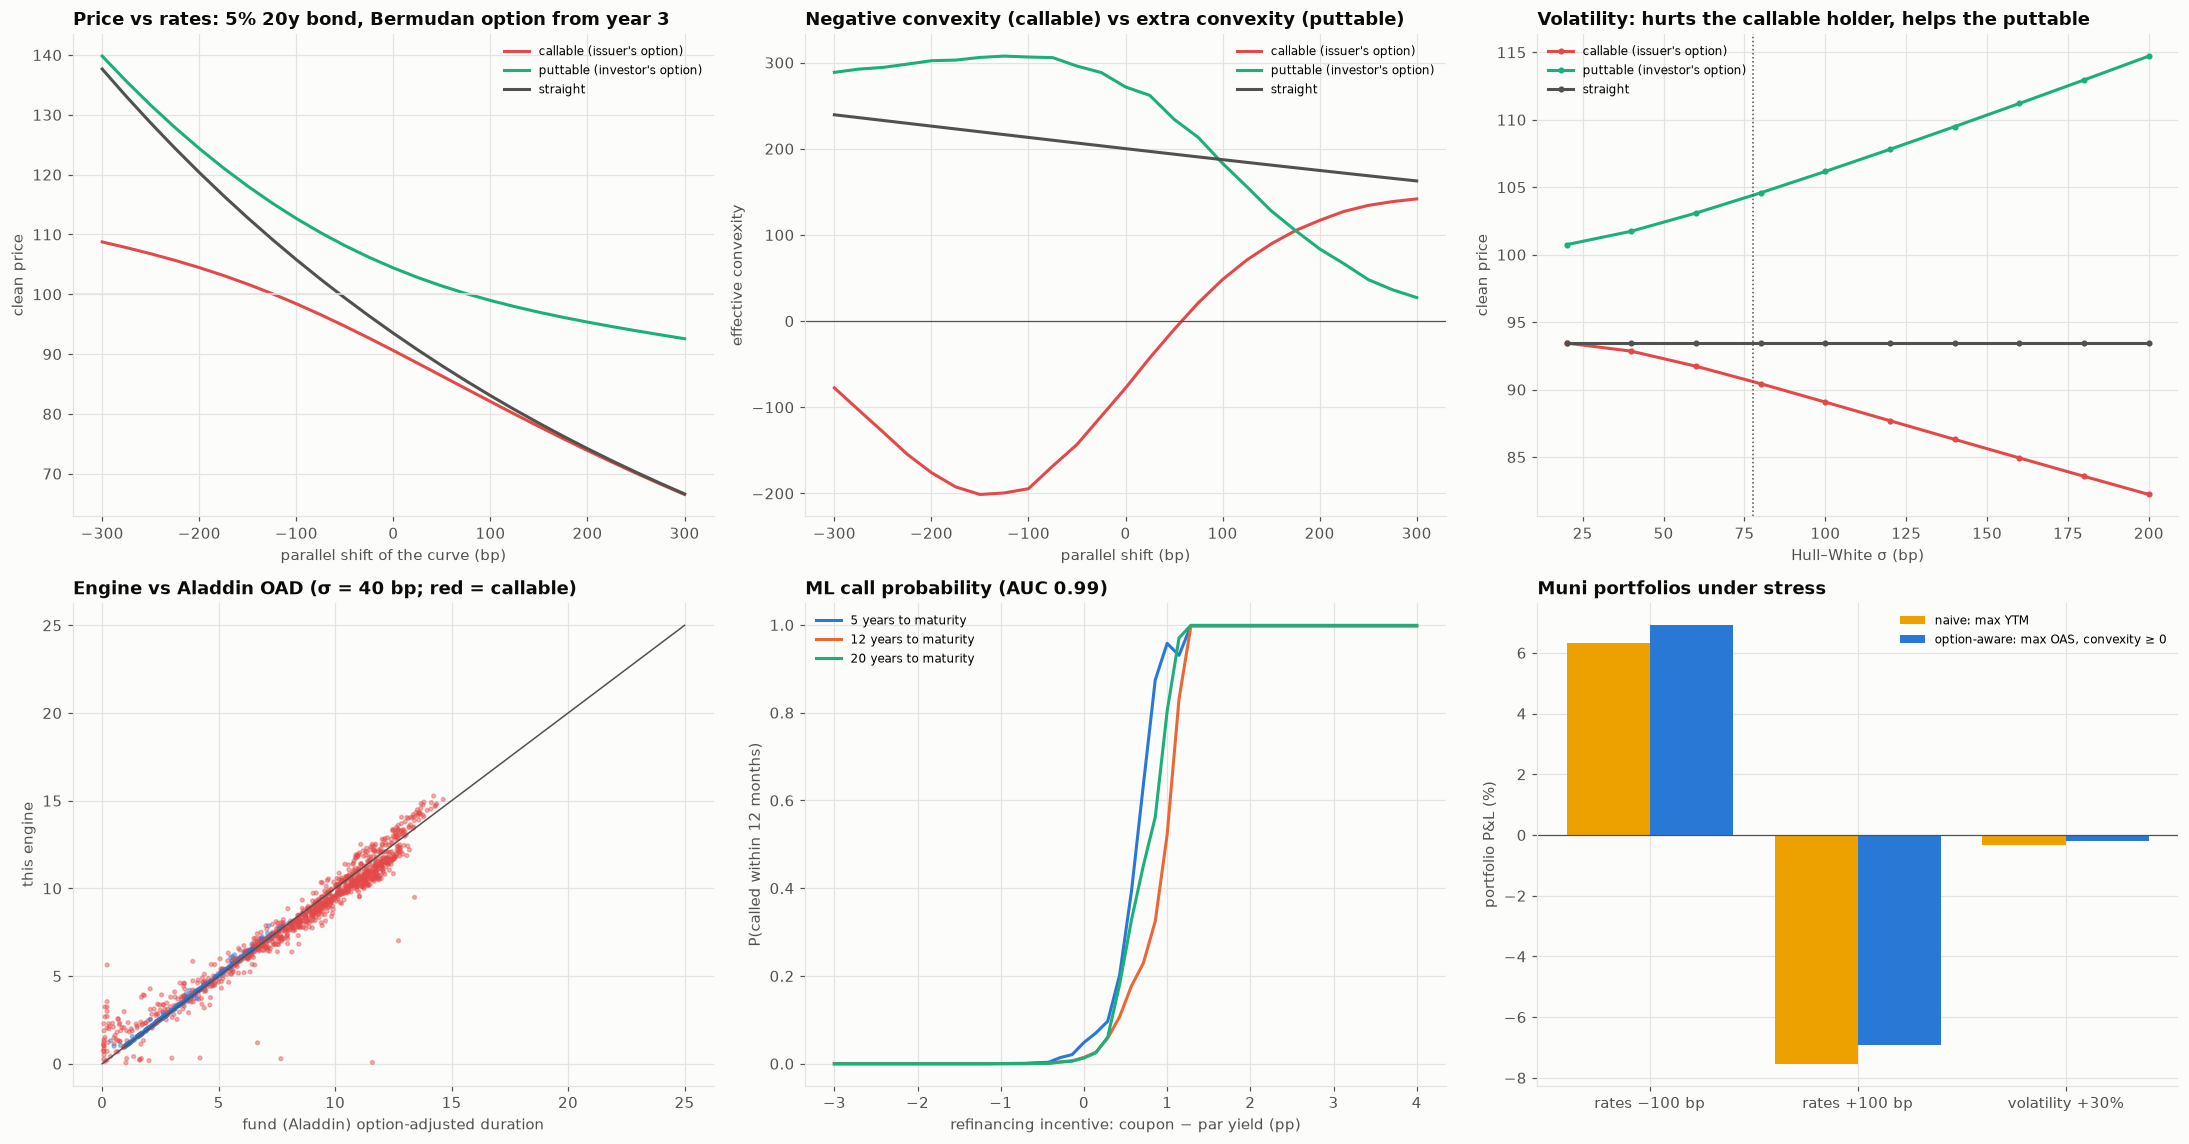

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(20, 10.5))
cols = {"straight": INK_2, "call": PALETTE[7], "put": PALETTE[2]}
lab = {
    "straight": "straight",
    "call": "callable (issuer's option)",
    "put": "puttable (investor's option)",
}
ax = axes[0, 0]
for k, g in prof.groupby("bond"):
    ax.plot(g["shift_bp"], g["price"], color=cols[k], label=lab[k])
ax.axhline(100, color=GRID, lw=1)
ax.set_xlabel("parallel shift of the curve (bp)")
ax.set_ylabel("clean price")
ax.set_title("Price vs rates: 5% 20y bond, Bermudan option from year 3")
ax.legend(fontsize=8)
ax = axes[0, 1]
for k, g in prof.groupby("bond"):
    ax.plot(g["shift_bp"], g["eff_convexity"], color=cols[k], label=lab[k])
ax.axhline(0, color=INK_2, lw=0.8)
ax.set_xlabel("parallel shift (bp)")
ax.set_ylabel("effective convexity")
ax.set_title("Negative convexity (callable) vs extra convexity (puttable)")
ax.legend(fontsize=8)
ax = axes[0, 2]
for k, g in vega.groupby("bond"):
    ax.plot(g["sigma_bp"], g["price"], "o-", color=cols[k], ms=3, label=lab[k])
ax.axvline(SIGMA * 1e4, color=INK_2, ls=":", lw=1)
ax.set_xlabel("Hull–White σ (bp)")
ax.set_ylabel("clean price")
ax.set_title("Volatility: hurts the callable holder, helps the puttable")
ax.legend(fontsize=8)
ax = axes[1, 0]
ax.scatter(
    samp["oad_fund"],
    samp["oad_model"],
    s=6,
    alpha=0.4,
    c=np.where(samp["callable_conv"], PALETTE[7], PALETTE[0]),
)
ax.plot([0, 25], [0, 25], color=INK_2, lw=1)
ax.set_xlabel("fund (Aladdin) option-adjusted duration")
ax.set_ylabel("this engine")
ax.set_title(
    f"Engine vs Aladdin OAD (σ = {best_sig * 1e4:.0f} bp; red = callable)"
)
ax = axes[1, 1]
inc = np.linspace(-3, 4, 50)
for yl, c in [(5, PALETTE[0]), (12, PALETTE[1]), (20, PALETTE[2])]:
    X_ = pd.DataFrame({
        "incentive": inc,
        "years_left": yl,
        "since_first": 1.0,
        "short_rate": zero(0.25) * 100,
        "slope_proxy": 0.0,
        "coupon": 5.0,
    })
    ax.plot(
        inc,
        call_clf.predict_proba(X_[CFE])[:, 1],
        color=c,
        label=f"{yl} years to maturity",
    )
ax.set_xlabel("refinancing incentive: coupon − par yield (pp)")
ax.set_ylabel("P(called within 12 months)")
ax.set_title(
    "ML call probability (AUC"
    f" {call_score.loc['LightGBM (all features)', 'AUC']:.2f})"
)
ax.legend(fontsize=8)
ax = axes[1, 2]
st = port.loc[[c for c in port.index if c.startswith("P&L")]]
xx = np.arange(len(st))
ax.bar(xx - 0.2, st.iloc[:, 0], 0.4, color=PALETTE[3], label=port.columns[0])
ax.bar(xx + 0.2, st.iloc[:, 1], 0.4, color=PALETTE[0], label=port.columns[1])
ax.set_xticks(xx)
ax.set_xticklabels(
    [c.replace("P&L ", "").replace(" (%)", "") for c in st.index]
)
ax.axhline(0, color=INK_2, lw=0.8)
ax.set_ylabel("portfolio P&L (%)")
ax.set_title("Muni portfolios under stress")
ax.legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "01_callable_puttable_ml_portfolio")
plt.show()

## 8. Reading the results and limitations

**Callable vs puttable.** Take the same 5% 20-year bond with a Bermudan option at par from year 3, priced on a Hull–White tree with σ = 78 bp. The tree's σ matches the 10-year Treasury's 67 bp/yr normal volatility.

| | Straight | Callable | Puttable |
|---|---|---|---|
| Price | 93.5 | **90.6** (call worth 2.9 points to the issuer) | **104.4** (put worth 10.9 points to the investor) |
| Option-adjusted duration | 12.1 | 9.2 | 6.5 years |
| Effective convexity | +200 | **−78** | +272 |

- **Rates fall 200 bp.** The callable's price is capped near 104 (the straight bond goes to 120), its duration collapses to 4.9 years and convexity is −176.
- **Rates rise 200 bp.** The puttable's price is floored near 95 and its duration shrinks to 3.2 years.
- **Volatility.** It moves the two in opposite directions: from σ = 20 to 200 bp, the callable loses about 11 points and the puttable gains about 14.
- **Monte Carlo cross-check.** Longstaff–Schwartz on 20,000 paths agrees with the tree to within 0.17–0.23 points, about the same gap as for the straight bond. So the residual is the Monte Carlo discretisation of discounting, not the exercise rule. In the simulation the issuer calls on 43% of paths, at a median of 8.5 years.

**ML 1 — call probability.** Across 250,000 bond/path/date observations from 300 random callables, the probability of a call within 12 months is learned with an AUC of **0.993** (LightGBM) vs **0.988** for a logistic regression on the refinancing incentive alone (Brier 0.010 vs 0.013).
- **The incentive explains almost everything.** The call probability jumps from near zero to near one as coupon minus par yield crosses about +0.5 to +1.2 points.
- **What LightGBM adds** is the maturity effect: short bonds are called at a lower incentive, because the option has less time value left.

The labels come from the model's *optimal* exercise. Real issuers call late and in batches, so on real call histories these AUCs would be much lower.

**Real data: the engine reproduces Aladdin's durations, with a lower volatility.**
- **The universe.** Of 7,023 MUB bonds, 76% are callable under the 10-year par-call convention. BlackRock's OAD is below the modified duration for 71%, and yield-to-worst is below yield-to-maturity for 40% (they trade to the call).

**Agreement.** With σ = 40 bp the tree's effective durations match the fund's OADs with a median error of **0.30 years and R² 0.96** (0.45 years on callables). At the Treasury-implied 78 bp the error doubles to 0.60 years, because higher volatility makes the call shorten duration too much.

Muni-market volatility implied by these durations is about half the Treasury normal volatility, plausible for the tax-exempt curve, which moves less than Treasuries.

- **The remaining errors** are mostly bonds whose actual call date departs from the 10-year convention. The official statements would fix that.

**ML 2 — surrogate pricer.**
- **Accuracy.** The MLP reproduces the tree with a test error of 0.32 price points and 0.12 years of duration. Across the 1,500 sampled munis, its durations sit a median 0.19 years from the tree's and 0.38 years from Aladdin's.
- **Speed.** It values all 7,023 bonds (OAS inversion and duration) in **0.7 seconds**, against about 8 ms per bond per volatility for the tree.

**ML 3 — what a 30% rise in volatility does to callable munis**, holding OAS fixed, with the control variate removing the surrogate's own error:

| Bucket | Price change (points) | Yield change |
|---|---|---|
| Callable now | −0.26 | **+7 bp** |
| Callable within 2 years | −0.19 | +4 bp |
| Call in 2–5 years | −0.25 | +3 bp |
| Call in 5–10 years | −0.45 | +5 bp |
| Non-callable | ≈ 0 | ≈ 0 |

The largest price losses come from the long-dated, at-the-money calls. The largest *yield* effects come from bonds already callable, because their option-adjusted durations are short.

**ML 4 — portfolio optimisation.** Two $100mm portfolios at 7 years OAD.

| | Naive YTM-maximiser | Option-aware |
|---|---|---|
| YTM | **5.36%** | 4.91% |
| Yield to worst | 4.81% | 4.62% |
| OAS | −20 bp | **+16 bp** |
| Effective convexity | −103 | 0 |
| Callable within 2 years | 48% | 15% |
| P&L, rates −100 bp | +6.3% | **+6.9%** |
| P&L, rates +100 bp | −7.5% | **−6.9%** |
| P&L, volatility +30% | −0.33% | **−0.21%** |

The naive portfolio's 45 bp of extra yield is mostly the price of the short calls it has sold. The option-aware portfolio earns 36 bp more option-adjusted spread and loses less in every scenario. (OAS is negative for many munis because they are discounted on the taxable Treasury curve; the comparison across bonds is what matters.)

**Limitations**
- **One-factor model.** Hull–White with a single mean reversion and constant volatility, calibrated to the Treasury curve. Munis really need their own tax-exempt curve and a volatility surface, and Hull–White normal rates allow negative rates in the far tails.
- **The call schedules are assumed.** Every bond is given the standard 10-year par call. Sinking funds, make-whole and extraordinary redemption provisions, pre-refunded bonds and premium calls are ignored. Puttable bonds are only modelled, because none trade in this universe.
- **Exercise is optimal.** The call-probability model learns optimal issuer exercise, not behaviour. Refinancing costs, tax-law constraints on advance refundings and issuer credit changes all delay real calls.
- **The surrogate is only as good as its training range.** It covers coupons of 1–6%, maturities up to 35 years and OAS of ±300 bp. Bonds outside these ranges should go back to the tree.
- **The portfolio LP is static.** It assumes linear objective and constraint functions of the weights, a single duration target, and no transaction costs or liquidity limits on munis, which trade infrequently.

In [11]:
prof.to_csv(OUT_DIR / "callable_puttable_profiles.csv", index=False)
check.to_csv(OUT_DIR / "tree_vs_lsm_check.csv")
call_score.to_csv(OUT_DIR / "call_probability_scores.csv")
agree.to_csv(OUT_DIR / "engine_vs_aladdin_oad.csv")
sur_err.to_csv(OUT_DIR / "surrogate_test_error.csv", header=["value"])
vol_tab.to_csv(OUT_DIR / "volatility_impact_by_call_bucket.csv")
port.to_csv(OUT_DIR / "portfolio_optimisation.csv")
mub[[
    "name",
    "coupon",
    "maturity",
    "price",
    "ytm",
    "ytw",
    "oad_fund",
    "mod_dur",
    "callable_conv",
    "oas_sur",
    "oad_sur",
    "dyield_vol_bp",
    "call_prob_12m",
]].to_csv(OUT_DIR / "muni_bond_analytics.csv", index=False)
print(
    "Outputs written:", ", ".join(sorted(p_.name for p_ in OUT_DIR.iterdir()))
)

Outputs written: 01_callable_puttable_ml_portfolio.png, call_probability_scores.csv, callable_puttable_profiles.csv, engine_vs_aladdin_oad.csv, muni_bond_analytics.csv, portfolio_optimisation.csv, surrogate_test_error.csv, tree_vs_lsm_check.csv, volatility_impact_by_call_bucket.csv


## References

### Finance and regulation

- Hull, J., & White, A. (1994). Numerical procedures for implementing term structure models I: Single-factor models. *The Journal of Derivatives, 2*(1), 7–16. https://doi.org/10.3905/jod.1994.407902
- Longstaff, F. A., & Schwartz, E. S. (2001). Valuing American options by simulation: A simple least-squares approach. *The Review of Financial Studies, 14*(1), 113–147. https://doi.org/10.1093/rfs/14.1.113
- Kalotay, A. J., Williams, G. O., & Fabozzi, F. J. (1993). A model for valuing bonds and embedded options. *Financial Analysts Journal, 49*(3), 35–46. https://doi.org/10.2469/faj.v49.n3.35
- Ang, A., Bhansali, V., & Xing, Y. (2010). Taxes on tax-exempt bonds. *The Journal of Finance, 65*(2), 565–601. https://doi.org/10.1111/j.1540-6261.2009.01545.x
- Brigo, D., & Mercurio, F. (2006). *Interest rate models: Theory and practice* (2nd ed.). Springer. https://doi.org/10.1007/978-3-540-34604-3

### Machine learning and deep learning

- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems, 30*. https://proceedings.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html
- Ferguson, R., & Green, A. (2018). Deeply learning derivatives. *arXiv*. https://arxiv.org/abs/1809.02233
- Huangfu, Q., & Hall, J. A. J. (2018). Parallelizing the dual revised simplex method. *Mathematical Programming Computation, 10*(1), 119–142. https://doi.org/10.1007/s12532-017-0130-5